# Lab Assignment 10 – Beat-level Arrhythmia Classification on MIT-BIH: RNN vs LSTM vs GRU

In [8]:
!pip install -q wfdb scipy scikit-learn seaborn matplotlib tqdm

In [9]:
import os, random, time, warnings
from collections import Counter
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from tqdm.auto import tqdm
import wfdb
from scipy.signal import butter, filtfilt
import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score,
                             confusion_matrix, classification_report)
warnings.filterwarnings('ignore')
SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
set_seed()
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', DEVICE)

Device: cpu


## Task 1 – Data Acquisition and Exploration

In [10]:
import os
import glob
import zipfile
import shutil

DB_DIR = 'mitdb'
ZIP_PATH = 'mitdb.zip'
URL = 'https://physionet.org/static/published-projects/mitdb/mit-bih-arrhythmia-database-1.0.0.zip'

if len(glob.glob(os.path.join(DB_DIR, '*.dat'))) < 48:
    for p in [DB_DIR, 'mitdb_tmp', ZIP_PATH]:
        if os.path.isdir(p): shutil.rmtree(p)
        elif os.path.exists(p): os.remove(p)

    # Try 16-connection parallel download via aria2c, fallback to curl with progress bar
    rc = os.system(f'aria2c -x 16 -s 16 -k 1M "{URL}" -o {ZIP_PATH}')
    if rc != 0 or not os.path.exists(ZIP_PATH):
        print("aria2c not found, falling back to curl...")
        os.system(f'curl -L --progress-bar "{URL}" -o {ZIP_PATH}')

    print("Extracting files...")
    with zipfile.ZipFile(ZIP_PATH, 'r') as zf:
        zf.extractall('mitdb_tmp')

    os.makedirs(DB_DIR, exist_ok=True)
    for root, _, files in os.walk('mitdb_tmp'):
        for fname in files:
            shutil.move(os.path.join(root, fname), os.path.join(DB_DIR, fname))

    shutil.rmtree('mitdb_tmp')
    os.remove(ZIP_PATH)
    print("Done!")

ALL_RECORDS = sorted([
    os.path.splitext(os.path.basename(p))[0]
    for p in glob.glob(os.path.join(DB_DIR, '*.hea'))
])
print(len(ALL_RECORDS), 'records:', ALL_RECORDS)

aria2c not found, falling back to curl...


sh: line 1: aria2c: command not found
######################################################################## 100.0%


Extracting files...
Done!
71 records: ['100', '101', '102', '103', '104', '105', '106', '107', '108', '109', '111', '112', '113', '114', '115', '116', '117', '118', '119', '121', '122', '123', '124', '200', '201', '202', '203', '205', '207', '208', '209', '210', '212', '213', '214', '215', '217', '219', '220', '221', '222', '223', '228', '230', '231', '232', '233', '234', 'x_108', 'x_109', 'x_111', 'x_112', 'x_113', 'x_114', 'x_115', 'x_116', 'x_117', 'x_121', 'x_122', 'x_123', 'x_124', 'x_220', 'x_221', 'x_222', 'x_223', 'x_228', 'x_230', 'x_231', 'x_232', 'x_233', 'x_234']


### Cleaning rules
* **Paced records removed:** 102, 104, 107, 217.
* **Non-beat annotations removed** (rhythm changes `+`, `~`, `|`, `"`, `x`, `[`, `]`, `!`, etc.) – only symbols that map to an AAMI beat class are kept.
* AAMI mapping: **N** = N, L, R, e, j · **S** = A, a, J, S · **V** = V, E · **F** = F · **Q** = /, f, Q.

In [12]:
PACED = ['102', '104', '107', '217']
AAMI = {**{s: 0 for s in ['N', 'L', 'R', 'e', 'j']},
        **{s: 1 for s in ['A', 'a', 'J', 'S']},
        **{s: 2 for s in ['V', 'E']},
        'F': 3,
        **{s: 4 for s in ['/', 'f', 'Q']}}
CLASSES = ['N', 'S', 'V', 'F', 'Q']
FS = 360

# Keep only the 48 main numeric MIT-BIH records before removing paced ones
ALL_RECORDS = sorted([r for r in ALL_RECORDS if r.isdigit()])
RECORDS = [r for r in ALL_RECORDS if r not in PACED]
print(len(RECORDS), 'records after removing paced ones')

# inter-patient split (de Chazal et al.)
DS1 = ['101','106','108','109','112','114','115','116','118','119','122','124','201','203','205','207','208','209','215','220','223','230']
DS2 = ['100','103','105','111','113','117','121','123','200','202','210','212','213','214','219','221','222','228','231','232','233','234']
VAL_RECS = ['115', '116', '119', '223']             # validation patients held out of DS1
TRAIN_RECS = [r for r in DS1 if r not in VAL_RECS]
TEST_RECS = DS2

assert set(DS1 + DS2) == set(RECORDS), f"Diff: {set(DS1 + DS2) ^ set(RECORDS)}"
print('train', len(TRAIN_RECS), '| val', len(VAL_RECS), '| test', len(TEST_RECS), 'patients')

44 records after removing paced ones
train 18 | val 4 | test 22 patients


### Signal inspection (raw vs filtered) – record 100

Leads: ['MLII', 'V5'] | fs = 360


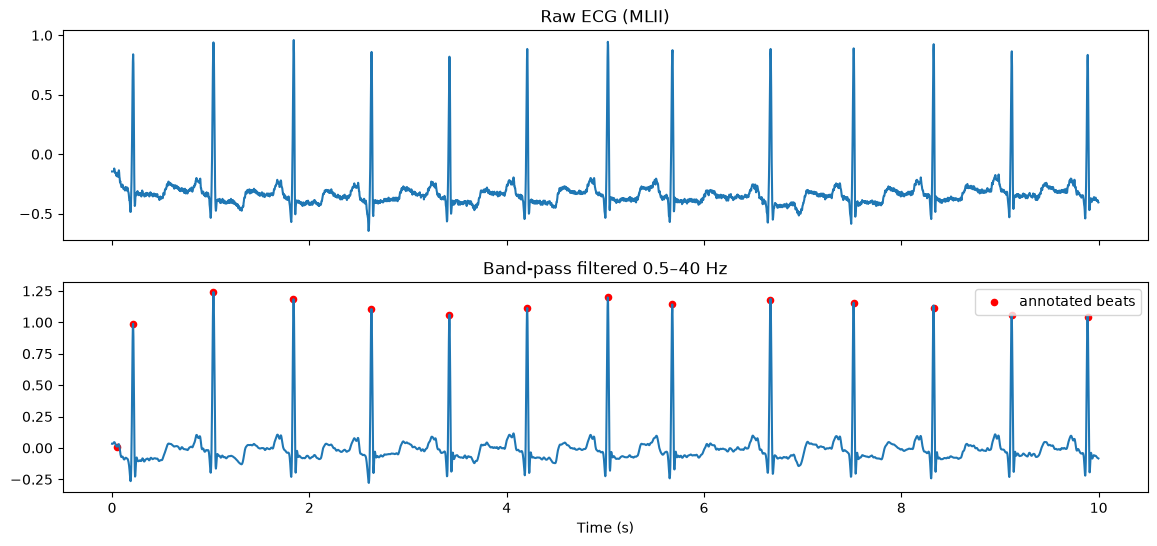

In [13]:
def bandpass(x, lo=0.5, hi=40.0, fs=FS, order=4):
    b, a = butter(order, [lo / (fs / 2), hi / (fs / 2)], btype='band')
    return filtfilt(b, a, x)

rec = wfdb.rdrecord(f'{DB_DIR}/100'); ann = wfdb.rdann(f'{DB_DIR}/100', 'atr')
print('Leads:', rec.sig_name, '| fs =', rec.fs)
raw = rec.p_signal[:, 0]; filt = bandpass(raw)
n = 10 * FS; t = np.arange(n) / FS
m = ann.sample < n
fig, ax = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
ax[0].plot(t, raw[:n]); ax[0].set_title('Raw ECG (MLII)')
ax[1].plot(t, filt[:n]); ax[1].scatter(ann.sample[m] / FS, filt[ann.sample[m]], c='r', s=20, label='annotated beats')
ax[1].set_title('Band-pass filtered 0.5–40 Hz'); ax[1].set_xlabel('Time (s)'); ax[1].legend(); plt.show()

## Task 2 – Preprocessing: filtering, segmentation, features, normalisation

In [14]:
HALF = 90                      # 90 samples before + 90 after R-peak = 180 samples (0.5 s)

def process_record(rid):
    rec = wfdb.rdrecord(f'{DB_DIR}/{rid}'); ann = wfdb.rdann(f'{DB_DIR}/{rid}', 'atr')
    ch = rec.sig_name.index('MLII') if 'MLII' in rec.sig_name else 0
    sig = bandpass(rec.p_signal[:, ch])
    samples, syms = np.array(ann.sample), np.array(ann.symbol)
    keep = np.array([s in AAMI for s in syms])           # drop non-beat annotations
    samples, syms = samples[keep], syms[keep]
    B, L, RR = [], [], []
    for i in range(1, len(samples) - 1):
        s = samples[i]
        if s - HALF < 0 or s + HALF > len(sig): continue
        seg = sig[s - HALF:s + HALF]
        seg = (seg - seg.mean()) / (seg.std() + 1e-8)            # per-beat z-score
        pre, post = samples[i] - samples[i - 1], samples[i + 1] - samples[i]
        local = np.mean(np.diff(samples[max(0, i - 10):i + 1]))   # mean of last <=10 RR intervals
        B.append(seg); L.append(AAMI[syms[i]]); RR.append([pre / FS, post / FS, pre / local])
    return np.array(B, dtype=np.float32), np.array(L), np.array(RR, dtype=np.float32)

Xs, ys, rrs, rids = [], [], [], []
for rid in tqdm(RECORDS, desc='Processing records'):
    b, l, r = process_record(rid)
    Xs.append(b); ys.append(l); rrs.append(r); rids += [rid] * len(l)
X, y, RR, rids = np.concatenate(Xs), np.concatenate(ys), np.concatenate(rrs), np.array(rids)
print('Beats:', X.shape, '| RR features:', RR.shape)

Processing records: 100%|██████████| 44/44 [00:05<00:00,  8.12it/s]


Beats: (100645, 180) | RR features: (100645, 3)


N    90042
S     2779
V     7007
F      802
Q       15
dtype: int64


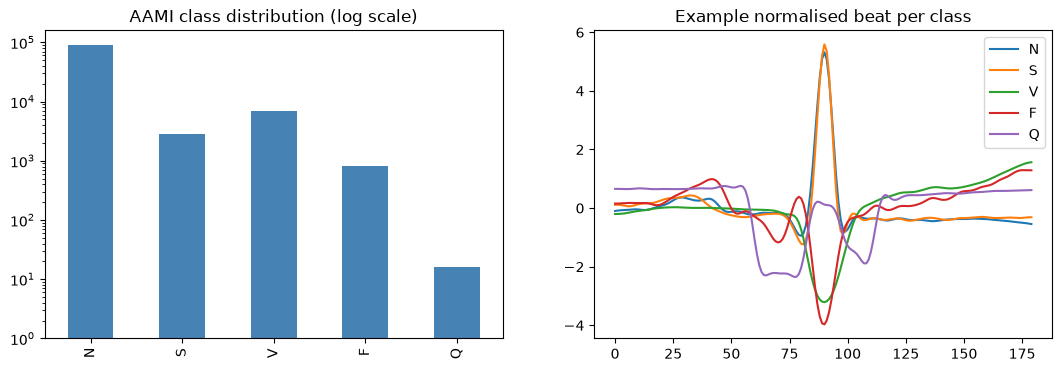

In [15]:
cnt = Counter(y)
dist = pd.Series({CLASSES[k]: cnt.get(k, 0) for k in range(5)}); print(dist)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
dist.plot.bar(ax=ax[0], color='steelblue', log=True); ax[0].set_title('AAMI class distribution (log scale)')
for k in range(5):
    if (y == k).any(): ax[1].plot(X[y == k][0], label=CLASSES[k])
ax[1].legend(); ax[1].set_title('Example normalised beat per class'); plt.show()

### Inter-patient split + class imbalance handling
* Train / validation / test are separated **by patient** (no beat of a test patient is ever seen in training).
* Imbalance: (1) the dominant class **N is randomly down-sampled** in the training set, (2) **class-weighted cross-entropy** (inverse frequency, classes that are absent get weight 0).
* RR features are standardised with training statistics.
* Each 180-sample beat is reshaped to **45 time steps × 4 features** (chunking) – this keeps the sequences short so that the vanilla RNN can be trained fairly and quickly. Set `CHUNK = 1` to feed one sample per step.

In [16]:
tr_m, va_m, te_m = (np.isin(rids, g) for g in (TRAIN_RECS, VAL_RECS, TEST_RECS))

# down-sample N in training
rng = np.random.RandomState(SEED); MAX_N = 20000
tr_idx = np.where(tr_m)[0]
n_idx = tr_idx[y[tr_idx] == 0]; other = tr_idx[y[tr_idx] != 0]
if len(n_idx) > MAX_N: n_idx = rng.choice(n_idx, MAX_N, replace=False)
tr_idx = rng.permutation(np.concatenate([n_idx, other]))
va_idx, te_idx = np.where(va_m)[0], np.where(te_m)[0]

pd.DataFrame({'train': np.bincount(y[tr_idx], minlength=5), 'val': np.bincount(y[va_idx], minlength=5),
              'test': np.bincount(y[te_idx], minlength=5)}, index=CLASSES)

,train,val,test
N,20000,7835,44218
S,869,74,1836
V,2762,1026,3219
F,400,14,388
Q,8,0,7


In [17]:
CHUNK = 4
rr_mu, rr_sd = RR[tr_idx].mean(0), RR[tr_idx].std(0) + 1e-8

def make_ds(idx):
    x = torch.tensor(X[idx]).reshape(len(idx), HALF * 2 // CHUNK, CHUNK)
    r = torch.tensor((RR[idx] - rr_mu) / rr_sd)
    return TensorDataset(x, r, torch.tensor(y[idx]))

BS = 256
train_dl = DataLoader(make_ds(tr_idx), batch_size=BS, shuffle=True)
val_dl   = DataLoader(make_ds(va_idx), batch_size=BS)
test_dl  = DataLoader(make_ds(te_idx), batch_size=BS)

counts = np.bincount(y[tr_idx], minlength=5).astype(float)
w = np.where(counts > 0, counts.sum() / (np.count_nonzero(counts) * np.maximum(counts, 1)), 0.0)
class_w = torch.tensor(w, dtype=torch.float32).to(DEVICE)
print('Class weights:', dict(zip(CLASSES, w.round(3))))

Class weights: {'N': np.float64(0.24), 'S': np.float64(5.533), 'V': np.float64(1.741), 'F': np.float64(12.02), 'Q': np.float64(600.975)}


## Task 3 – Models: RNN, LSTM, GRU (identical architecture & hyper-parameters)

In [18]:
class SeqNet(nn.Module):
    def __init__(self, kind, in_dim=CHUNK, hidden=64, layers=2, n_cls=5, rr_dim=3, dropout=0.3):
        super().__init__()
        cell = {'RNN': nn.RNN, 'LSTM': nn.LSTM, 'GRU': nn.GRU}[kind]
        self.rnn = cell(in_dim, hidden, layers, batch_first=True, dropout=dropout)
        self.head = nn.Sequential(nn.Linear(hidden + rr_dim, 64), nn.ReLU(), nn.Dropout(dropout), nn.Linear(64, n_cls))
    def forward(self, x, rr):
        out, _ = self.rnn(x)
        return self.head(torch.cat([out[:, -1], rr], 1))

EPOCHS, PATIENCE, LR = 40, 7, 1e-3

def evaluate(model, dl, crit=None):
    model.eval(); P, Y, tot, n = [], [], 0.0, 0
    with torch.no_grad():
        for x, r, t in dl:
            x, r, t = x.to(DEVICE), r.to(DEVICE), t.to(DEVICE)
            o = model(x, r)
            if crit is not None: tot += crit(o, t).item() * len(t); n += len(t)
            P.append(o.argmax(1).cpu().numpy()); Y.append(t.cpu().numpy())
    return (tot / max(n, 1)), np.concatenate(P), np.concatenate(Y)

def train_model(kind):
    set_seed()
    model = SeqNet(kind).to(DEVICE)
    crit = nn.CrossEntropyLoss(weight=class_w)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    hist = dict(tr=[], va=[], va_f1=[]); best, wait, state = 1e9, 0, None; t0 = time.time()
    for ep in range(1, EPOCHS + 1):
        model.train(); tot, n = 0.0, 0
        for x, r, t in train_dl:
            x, r, t = x.to(DEVICE), r.to(DEVICE), t.to(DEVICE)
            loss = crit(model(x, r), t)
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
            tot += loss.item() * len(t); n += len(t)
        vl, vp, vy = evaluate(model, val_dl, crit)
        vf1 = f1_score(vy, vp, average='macro', zero_division=0)
        hist['tr'].append(tot / n); hist['va'].append(vl); hist['va_f1'].append(vf1)
        print(f'[{kind}] epoch {ep:02d} train {tot/n:.4f} | val {vl:.4f} | val macro-F1 {vf1:.3f}')
        if vl < best - 1e-4: best, wait, state = vl, 0, {k: v.clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= PATIENCE: print(f'[{kind}] early stopping'); break
    model.load_state_dict(state)
    return model, hist, time.time() - t0

models, hists, times = {}, {}, {}
for kind in ['RNN', 'LSTM', 'GRU']:
    models[kind], hists[kind], times[kind] = train_model(kind)
    print(f'{kind}: {sum(p.numel() for p in models[kind].parameters()):,} params, {times[kind]:.0f}s\n')

[RNN] epoch 01 train 1.3108 | val 1.0207 | val macro-F1 0.342
[RNN] epoch 02 train 1.1011 | val 0.7239 | val macro-F1 0.437
[RNN] epoch 03 train 0.9570 | val 0.7584 | val macro-F1 0.448
[RNN] epoch 04 train 0.9314 | val 0.5824 | val macro-F1 0.464
[RNN] epoch 05 train 0.9145 | val 0.4803 | val macro-F1 0.535
[RNN] epoch 06 train 0.7729 | val 0.6725 | val macro-F1 0.424
[RNN] epoch 07 train 0.7839 | val 0.5157 | val macro-F1 0.485
[RNN] epoch 08 train 0.6975 | val 0.6243 | val macro-F1 0.449
[RNN] epoch 09 train 0.6597 | val 0.7217 | val macro-F1 0.375
[RNN] epoch 10 train 0.6801 | val 0.8643 | val macro-F1 0.382
[RNN] epoch 11 train 0.5589 | val 0.6073 | val macro-F1 0.432
[RNN] epoch 12 train 0.6253 | val 0.6239 | val macro-F1 0.431
[RNN] early stopping
RNN: 17,477 params, 49s

[LSTM] epoch 01 train 1.4142 | val 0.9009 | val macro-F1 0.382
[LSTM] epoch 02 train 0.9779 | val 0.7659 | val macro-F1 0.395
[LSTM] epoch 03 train 0.8567 | val 0.7300 | val macro-F1 0.317
[LSTM] epoch 04 train

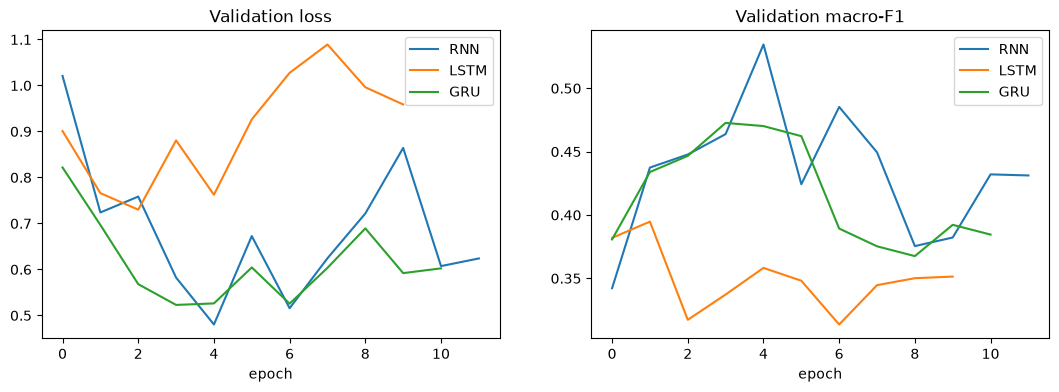

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for k, h in hists.items():
    ax[0].plot(h['va'], label=k); ax[1].plot(h['va_f1'], label=k)
ax[0].set_title('Validation loss'); ax[1].set_title('Validation macro-F1')
for a in ax: a.set_xlabel('epoch'); a.legend()
plt.show()

### Test-set comparison (inter-patient: DS2 patients)

In [20]:
rows, preds = [], {}
for kind, m in models.items():
    _, p, t = evaluate(m, test_dl); preds[kind] = p
    present = sorted(np.unique(t))                          # classes that actually occur in the test set
    pr, rc, f1, _ = precision_recall_fscore_support(t, p, labels=present, average='macro', zero_division=0)
    _, _, wf1, _ = precision_recall_fscore_support(t, p, labels=present, average='weighted', zero_division=0)
    rows.append(dict(Model=kind, Accuracy=accuracy_score(t, p), Precision_macro=pr, Recall_macro=rc,
                     F1_macro=f1, F1_weighted=wf1, Params=sum(q.numel() for q in m.parameters()), Train_time_s=times[kind]))
results = pd.DataFrame(rows).set_index('Model').round(4)
y_test = t
results

,Accuracy,Precision_macro,Recall_macro,F1_macro,F1_weighted,Params,Train_time_s
Model,,,,,,,
RNN,0.6086,0.2878,0.5018,0.2796,0.6984,17477,48.8629
LSTM,0.4672,0.2729,0.4536,0.2358,0.5844,55877,74.2416
GRU,0.5537,0.2787,0.4250,0.2585,0.6649,43077,104.2768


 RNN
              precision    recall  f1-score   support

           N       0.99      0.60      0.75     44218
           S       0.21      0.30      0.25      1836
           V       0.19      0.81      0.31      3219
           F       0.05      0.79      0.09       388
           Q       0.00      0.00      0.00         7

    accuracy                           0.61     49668
   macro avg       0.29      0.50      0.28     49668
weighted avg       0.90      0.61      0.70     49668

 LSTM
              precision    recall  f1-score   support

           N       0.99      0.45      0.62     44218
           S       0.03      0.11      0.05      1836
           V       0.32      0.83      0.46      3219
           F       0.02      0.88      0.05       388
           Q       0.00      0.00      0.00         7

    accuracy                           0.47     49668
   macro avg       0.27      0.45      0.24     49668
weighted avg       0.90      0.47      0.58     49668

 GRU
      

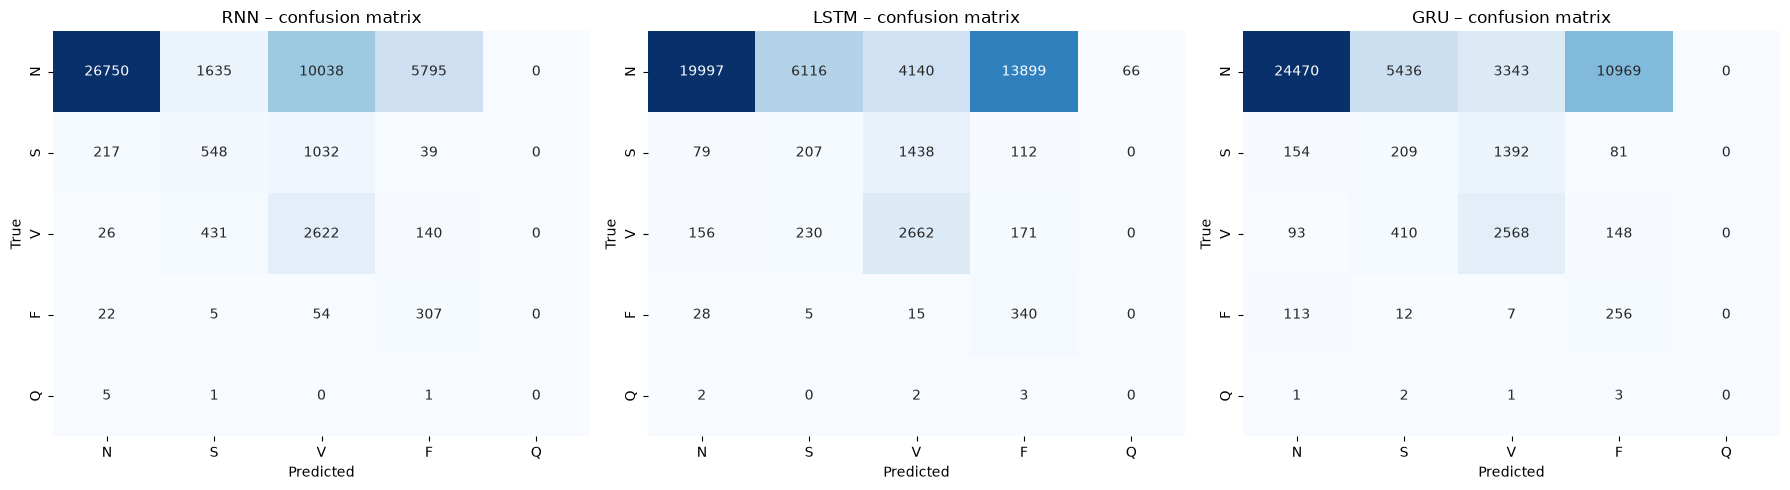

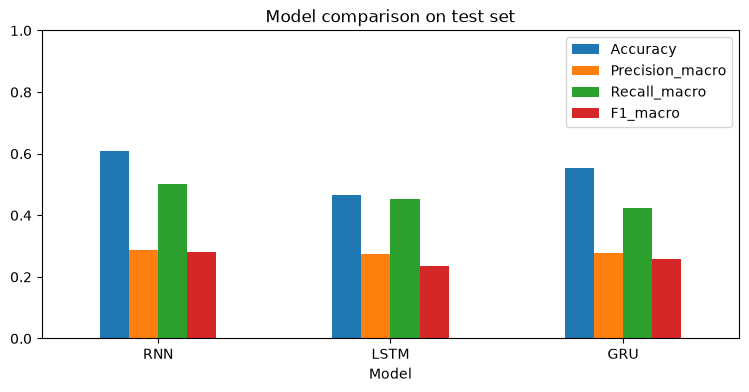

In [21]:
for kind in preds:
    print('=' * 60, '\n', kind)
    print(classification_report(y_test, preds[kind], labels=range(5), target_names=CLASSES, zero_division=0))

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for a, kind in zip(ax, preds):
    cm = confusion_matrix(y_test, preds[kind], labels=range(5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES, ax=a, cbar=False)
    a.set_title(f'{kind} – confusion matrix'); a.set_xlabel('Predicted'); a.set_ylabel('True')
plt.tight_layout(); plt.show()

results[['Accuracy', 'Precision_macro', 'Recall_macro', 'F1_macro']].plot.bar(figsize=(9, 4), ylim=(0, 1))
plt.title('Model comparison on test set'); plt.xticks(rotation=0); plt.show()